# Mini-Projeto: Aprendizado por Reforço no MountainCar

**Integrantes:** Deborah Ferreira (599070), Andrezza, João Lucas e Henrique Sanchez  
**Grupo:** dois alunos de mestrado e dois de graduação.

Neste trabalho, comparamos três métodos tabulares no MountainCar. Como posição e velocidade são valores contínuos, usamos duas grades para transformar cada observação em um estado discreto.

## Tarefa A: Modelagem do Espaço de Estados

Usamos uma grade uniforme de 10×10 e outra de 30×30. A primeira junta mais observações no mesmo estado; a segunda separa os estados em mais grupos.

In [1]:
%pip -q install gymnasium==1.2.3 numpy==2.2.6 pandas==2.3.3 numba==0.61.2 matplotlib==3.10.7 seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


C:\Users\Admin\Documents\Reinforcement-Learning\.venv\Scripts\python.exe: No module named pip


In [2]:
import numpy as np

def estado_discreto(obs, grade):
    pos = max(0, min(grade-1, int((obs[0] + 1.2) / 1.8 * grade)))
    vel = max(0, min(grade-1, int((obs[1] + .07) / .14 * grade)))
    return pos * grade + vel

## Tarefa B: Implementação dos Agentes Tabulares

Implementamos Q-learning, SARSA(?) e Dyna-Q. As funções de treino e as escolhas usadas na comparação estão descritas a seguir.

### Protocolo dos três agentes

Q-learning é o baseline de uma atualização por interação. SARSA(λ) usa traços
acumulativos, reiniciados a cada episódio, e a próxima ação da política ε-greedy no alvo.
Dyna-Q usa a última transição observada por par estado–ação e N atualizações simuladas
por interação, amostrando pares observados uniformemente com reposição. Somente
`terminated` remove o bootstrap; `truncated` encerra o episódio e preserva o bootstrap.

O custo é o número de entradas Q[s,a] às quais se aplica uma atualização: uma no
Q-learning, 1+N no Dyna-Q e uma por traço não nulo no SARSA(λ), mesmo quando o erro TD
é zero. É uma medida de atualizações, não uma equivalência de tempo de CPU.

A busca separada (`Busca_Agentes.ipynb`) testa 20 configurações × 10 seeds (0–9),
600 episódios cada: duas grades, dois perfis conjuntos (α, γ, decaimento ε),
λ ∈ {0,5; 0,9} para SARSA e N ∈ {5,20} para Dyna-Q. Q-learning cobre N=0.
Os perfis são (0,1; 0,99; 0,99) e (0,3; 0,999; 0,995), com ε inicial 1 e piso 0,05.
A seleção usa a maior recompensa média nos últimos 100 episódios, com peso igual
por seed; empates favorecem menor custo Q. Seleciona-se uma configuração por
algoritmo/grade. “Melhor” significa apenas melhor entre as candidatas testadas.

A avaliação final usa 10 seeds novas (100–109) para cada uma das seis configurações,
totalizando 60 treinamentos. As métricas são de treinamento com exploração.
O código abaixo é autocontido: no Colab vazio treina e grava resultados; no repositório
pode reutilizar os CSVs e tabelas Q salvos. Defina `REUTILIZAR_RESULTADOS=False` para
refazer os treinos. Se modificar o código ou o protocolo, desative a reutilização.


In [3]:
# O Numba só acelera os laços de atualização.
from numba import njit

@njit
def iniciar_seed(seed):
    np.random.seed(seed)

@njit
def escolher_acao(q, s, epsilon):
    if np.random.random() < epsilon:
        return np.random.randint(3)
    melhores = np.flatnonzero(q[s] == q[s].max())
    return melhores[np.random.randint(len(melhores))]

@njit
def atualizar_q(q, s, a, r, ns, terminou, alpha, gamma):
    alvo = r if terminou else r + gamma * q[ns].max()
    q[s, a] += alpha * (alvo - q[s, a])

@njit
def atualizar_sarsa(q, tracos, s, a, r, ns, na, terminou, alpha, gamma, lam):
    alvo = r if terminou else r + gamma * q[ns, na]
    erro = alvo - q[s, a]
    tracos[s, a] += 1
    atualizacoes = 0
    for i in range(q.shape[0]):
        for j in range(3):
            if tracos[i, j] != 0:
                q[i, j] += alpha * erro * tracos[i, j]
                tracos[i, j] *= gamma * lam
                atualizacoes += 1
    return atualizacoes

@njit
def atualizar_dyna(q, s, a, r, ns, terminou, alpha, gamma, n,
                   recompensas, proximos, terminais, vistos, pares, quantidade):
    atualizar_q(q, s, a, r, ns, terminou, alpha, gamma)
    par = s * 3 + a
    if not vistos[par]:
        vistos[par] = True
        pares[quantidade] = par
        quantidade += 1
    recompensas[par], proximos[par], terminais[par] = r, ns, terminou
    for _ in range(n):
        par = pares[np.random.randint(quantidade)]
        ss, aa = par // 3, par % 3
        atualizar_q(q, ss, aa, recompensas[par], proximos[par],
                    terminais[par], alpha, gamma)
    return quantidade

## Tarefa C: Avaliação Experimental e Reprodutibilidade

Cada execução usa uma seed registrada. Os arquivos CSV guardam recompensa, passos, sucesso e atualizações de Q por episódio, além dos totais acumulados.

In [4]:
import time
from pathlib import Path
import gymnasium as gym
import pandas as pd

EPISODIOS = 600
PASTA = Path('resultados_comparacao')

def configuracoes():
    opcoes = []
    perfis = [(0.1, 0.99, 0.99), (0.3, 0.999, 0.995)]
    for grade in (10, 30):
        for p, (alpha, gamma, decaimento) in enumerate(perfis):
            base = dict(grid=grade, alpha=alpha, gamma=gamma,
                        epsilon_initial=1.0, epsilon_min=0.05,
                        epsilon_decay=decaimento)
            opcoes.append(dict(base, config_id=f'q_g{grade}_p{p}',
                               algorithm='Q-learning', planning_steps=0, **{'lambda': 0.0}))
            for lam in (0.5, 0.9):
                opcoes.append(dict(base, config_id=f'sarsa_g{grade}_p{p}_l{int(lam*10)}',
                                   algorithm='SARSA(lambda)', planning_steps=0,
                                   **{'lambda': lam}))
            for n in (5, 20):
                opcoes.append(dict(base, config_id=f'dyna_g{grade}_p{p}_n{n}',
                                   algorithm='Dyna-Q', planning_steps=n, **{'lambda': 0.0}))
    return opcoes

def treinar(config, seed, fase):
    grade, algoritmo = config['grid'], config['algorithm']
    alpha, gamma = config['alpha'], config['gamma']
    q = np.zeros((grade * grade, 3))
    tracos = np.zeros_like(q)
    tamanho = q.size
    recompensas = np.zeros(tamanho)
    proximos = np.zeros(tamanho, dtype=np.int64)
    terminais = np.zeros(tamanho, dtype=np.bool_)
    vistos = np.zeros(tamanho, dtype=np.bool_)
    pares = np.zeros(tamanho, dtype=np.int64)
    quantidade = 0

    # A primeira chamada compila as funções. Reiniciamos a seed antes do treino.
    iniciar_seed(0)
    escolher_acao(q, 0, 0.0)
    if algoritmo == 'SARSA(lambda)':
        atualizar_sarsa(q.copy(), tracos.copy(), 0, 0, -1.0, 1, 1,
                        False, alpha, gamma, config['lambda'])
    elif algoritmo == 'Dyna-Q':
        atualizar_dyna(q.copy(), 0, 0, -1.0, 1, False, alpha, gamma,
                       config['planning_steps'], recompensas.copy(), proximos.copy(),
                       terminais.copy(), vistos.copy(), pares.copy(), 0)
    else:
        atualizar_q(q.copy(), 0, 0, -1.0, 1, False, alpha, gamma)
    iniciar_seed(seed)

    ambiente = gym.make('MountainCar-v0')
    ambiente.action_space.seed(seed)
    registros, passos_totais, atualizacoes_totais = [], 0, 0
    inicio = time.perf_counter()
    try:
        for episodio in range(EPISODIOS):
            obs, _ = ambiente.reset(seed=seed if episodio == 0 else None)
            tracos.fill(0)
            epsilon = max(config['epsilon_min'],
                          config['epsilon_initial'] * config['epsilon_decay'] ** episodio)
            estado = estado_discreto(obs, grade)
            acao = escolher_acao(q, estado, epsilon)
            recompensa_total, passos, atualizacoes = 0, 0, 0
            while True:
                obs, recompensa, terminou, truncou, _ = ambiente.step(acao)
                proximo = estado_discreto(obs, grade)
                if algoritmo == 'SARSA(lambda)':
                    na = escolher_acao(q, proximo, epsilon) if not terminou else 0
                    atualizacoes += atualizar_sarsa(q, tracos, estado, acao, recompensa,
                        proximo, na, terminou, alpha, gamma, config['lambda'])
                elif algoritmo == 'Dyna-Q':
                    quantidade = atualizar_dyna(q, estado, acao, recompensa, proximo,
                        terminou, alpha, gamma, config['planning_steps'], recompensas,
                        proximos, terminais, vistos, pares, quantidade)
                    atualizacoes += 1 + config['planning_steps']
                else:
                    atualizar_q(q, estado, acao, recompensa, proximo,
                                terminou, alpha, gamma)
                    atualizacoes += 1
                recompensa_total += recompensa
                passos += 1
                passos_totais += 1
                if terminou or truncou:
                    break
                estado = proximo
                acao = na if algoritmo == 'SARSA(lambda)' else escolher_acao(q, estado, epsilon)
            atualizacoes_totais += atualizacoes
            registros.append(dict(**config, phase=fase, seed=seed, episode=episodio+1,
                                  episode_reward=recompensa_total, episode_steps=passos,
                                  cumulative_steps=passos_totais,
                                  episode_q_updates=atualizacoes, q_updates=atualizacoes_totais,
                                  success=bool(terminou), epsilon=epsilon,
                                  elapsed_seconds=time.perf_counter()-inicio))
    finally:
        ambiente.close()
    return pd.DataFrame(registros), q

def rodar(configs, seeds, fase):
    PASTA.mkdir(exist_ok=True)
    dados = []
    for config in configs:
        for seed in seeds:
            arquivo = PASTA / f'{fase}_{config["config_id"]}_seed{seed}.csv'
            tabela_q = PASTA / f'{config["config_id"]}_seed{seed}_q.npy'
            if arquivo.exists() and (fase == 'busca' or tabela_q.exists()):
                resultado = pd.read_csv(arquivo)
            else:
                resultado, q = treinar(config, seed, fase)
                resultado.to_csv(arquivo, index=False)
                if fase == 'avaliacao':
                    np.save(tabela_q, q)
            dados.append(resultado)
        print(config['config_id'], 'concluído')
    dados = pd.concat(dados, ignore_index=True)
    dados.to_csv(PASTA / f'{fase}.csv', index=False)
    return dados

def resumo(dados):
    ultimos = dados[dados.episode > EPISODIOS - 100]
    chaves = ['config_id', 'algorithm', 'grid', 'seed']
    por_seed = ultimos.groupby(chaves, as_index=False).agg(
        final_reward=('episode_reward', 'mean'), success_rate=('success', 'mean'))
    custo = dados.groupby(chaves, as_index=False).agg(
        total_q_updates=('q_updates', 'max'), total_steps=('cumulative_steps', 'max'))
    por_seed = por_seed.merge(custo, on=chaves)
    return por_seed.groupby(chaves[:-1], as_index=False).agg(
        mean_final_reward=('final_reward', 'mean'),
        std_final_reward=('final_reward', 'std'),
        mean_success_rate=('success_rate', 'mean'),
        mean_q_updates=('total_q_updates', 'mean'),
        mean_steps=('total_steps', 'mean'),
        seeds=('seed', 'nunique')).sort_values(
            ['mean_final_reward', 'mean_q_updates'], ascending=[False, True])

In [5]:
# Configurações escolhidas na busca (seeds 0 a 9).
melhores = [
  {
    "config_id": "q_g10_p0",
    "algorithm": "Q-learning",
    "planning_steps": 0,
    "lambda": 0.0,
    "grid": 10,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_decay": 0.99
  },
  {
    "config_id": "sarsa_g10_p0_l9",
    "algorithm": "SARSA(lambda)",
    "planning_steps": 0,
    "lambda": 0.9,
    "grid": 10,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_decay": 0.99
  },
  {
    "config_id": "dyna_g10_p0_n5",
    "algorithm": "Dyna-Q",
    "planning_steps": 5,
    "lambda": 0.0,
    "grid": 10,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_decay": 0.99
  },
  {
    "config_id": "dyna_g30_p0_n5",
    "algorithm": "Dyna-Q",
    "planning_steps": 5,
    "lambda": 0.0,
    "grid": 30,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_decay": 0.99
  },
  {
    "config_id": "q_g30_p1",
    "algorithm": "Q-learning",
    "planning_steps": 0,
    "lambda": 0.0,
    "grid": 30,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.3,
    "gamma": 0.999,
    "epsilon_decay": 0.995
  },
  {
    "config_id": "sarsa_g30_p1_l9",
    "algorithm": "SARSA(lambda)",
    "planning_steps": 0,
    "lambda": 0.9,
    "grid": 30,
    "epsilon_initial": 1.0,
    "epsilon_min": 0.05,
    "alpha": 0.3,
    "gamma": 0.999,
    "epsilon_decay": 0.995
  }
]

# Com os CSVs salvos, esta célula os lê. Em um Colab vazio, faz os treinos.
avaliacao = rodar(melhores, range(100, 110), 'avaliacao')
resumo_final = resumo(avaliacao)
resumo_final.to_csv(PASTA / 'resumo_avaliacao.csv', index=False)
display(resumo_final)

q_g10_p0 concluído
sarsa_g10_p0_l9 concluído
dyna_g10_p0_n5 concluído
dyna_g30_p0_n5 concluído
q_g30_p1 concluído
sarsa_g30_p1_l9 concluído


,config_id,algorithm,grid,mean_final_reward,std_final_reward,mean_success_rate,mean_q_updates,mean_steps,seeds
4,sarsa_g10_p0_l9,SARSA(lambda),10,-160.645,6.818405,0.860,2207028.8,104348.9,10
5,sarsa_g30_p1_l9,SARSA(lambda),30,-190.185,7.966766,0.329,6523062.5,118878.5,10
2,q_g10_p0,Q-learning,10,-192.653,4.238346,0.266,118259.8,118259.8,10
1,dyna_g30_p0_n5,Dyna-Q,30,-194.800,4.430362,0.256,708826.8,118137.8,10
0,dyna_g10_p0_n5,Dyna-Q,10,-199.691,0.427901,0.017,718861.8,119810.3,10
3,q_g30_p1,Q-learning,30,-199.911,0.119578,0.010,119987.5,119987.5,10


A tabela foi calculada com as 10 seeds reservadas para a avaliação. Cada seed teve 600 episódios. O tempo de execução fica registrado nos CSVs, mas não o usamos para comparar os agentes: foi medido em uma máquina compartilhada e depende da execução local.

## 4.1 Gráficos de aprendizagem

Para cada grade, mostramos a média das 10 seeds por episódio. Usamos os mesmos limites de eixo nas duas grades, para facilitar a comparação.

- **Passos:** eixo de 0 a 200, com uma pequena margem acima. Chegar a 200 passos não significa sucesso: pode ser apenas o limite do episódio.
- **Atualizações de Q:** escala logarítmica, de 100 a 20.000. Isso permite ver os três agentes mesmo com custos bem diferentes. Distâncias iguais nesse eixo representam proporções iguais.
- **Sucesso:** de 0% a 100%. Como são 10 seeds, a média em cada episódio varia em múltiplos de 10%.

Q-learning faz uma atualização por passo; Dyna-Q, com N=5, faz seis. Quando os episódios duram perto de 200 passos, os custos ficam perto de 200 e 1.200. Portanto, as curvas quase horizontais refletem episódios com duração parecida. O SARSA atualiza várias entradas com traços de elegibilidade, e sua contagem varia mais.

As faixas mostram o IC t de 95% aproximado: média ± 2,262 erros padrão entre as 10 seeds (9 graus de liberdade). Limitamos as faixas de passos e sucesso aos valores possíveis. Não aplicamos suavização. Os CSVs também guardam passos e atualizações acumulados.


O gráfico de sucesso é complementar: 60% no episódio 500 significa que 6 das 10 seeds atingiram a meta em seus respectivos episódios 500. Esse valor não é acumulado desde o início do treino. Os gráficos exigidos pelo README são os de passos e atualizações de Q.


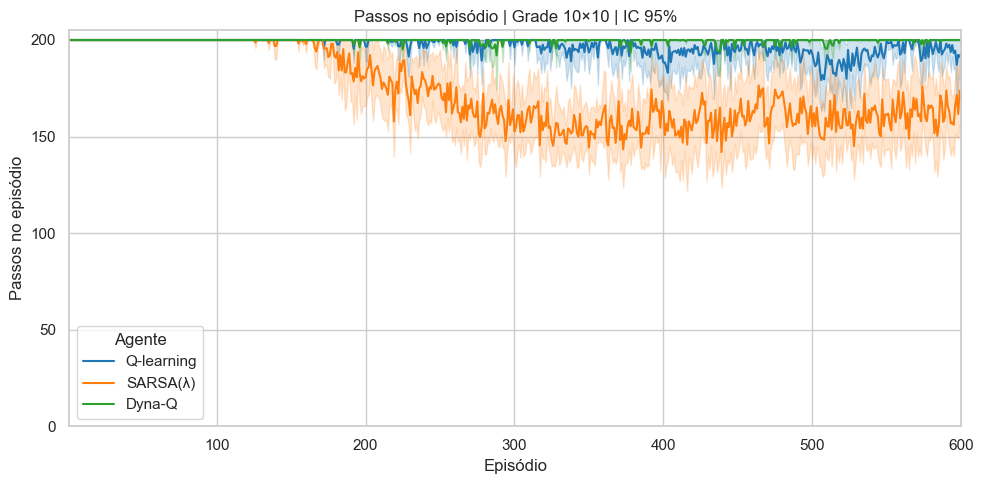

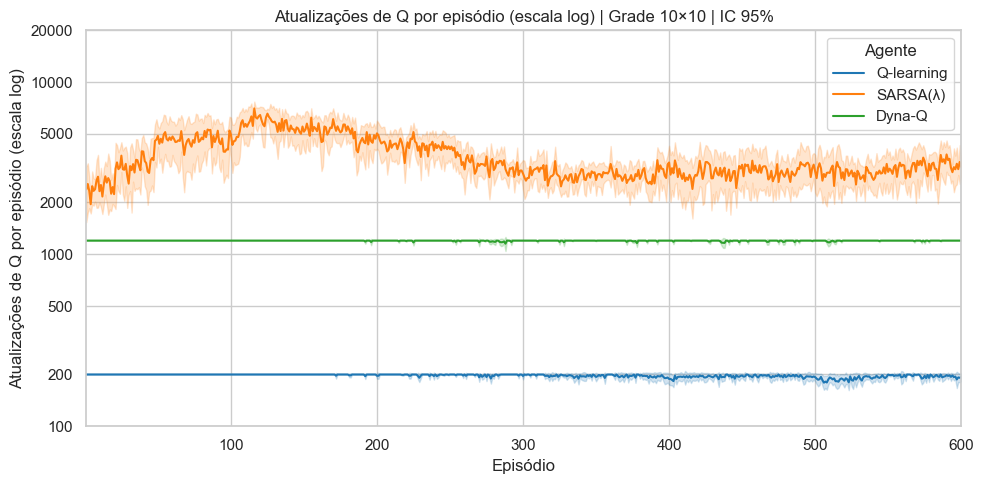

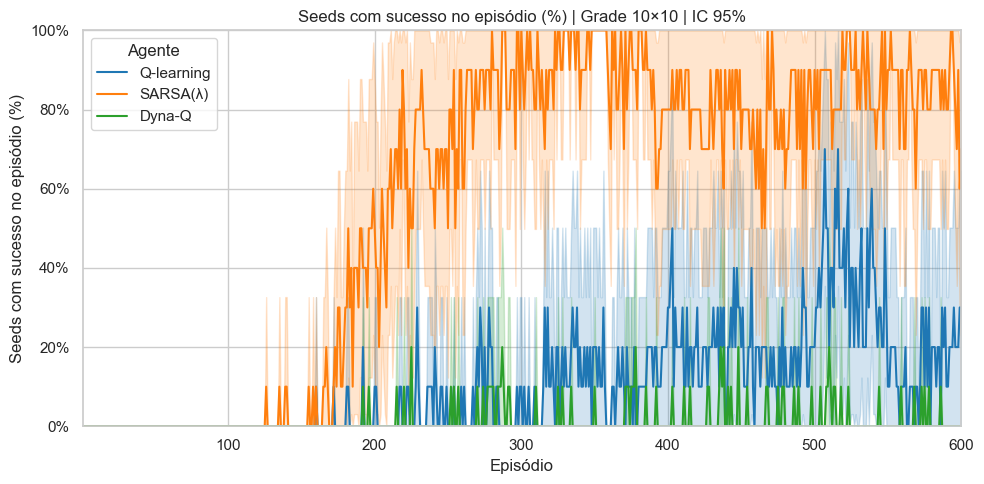

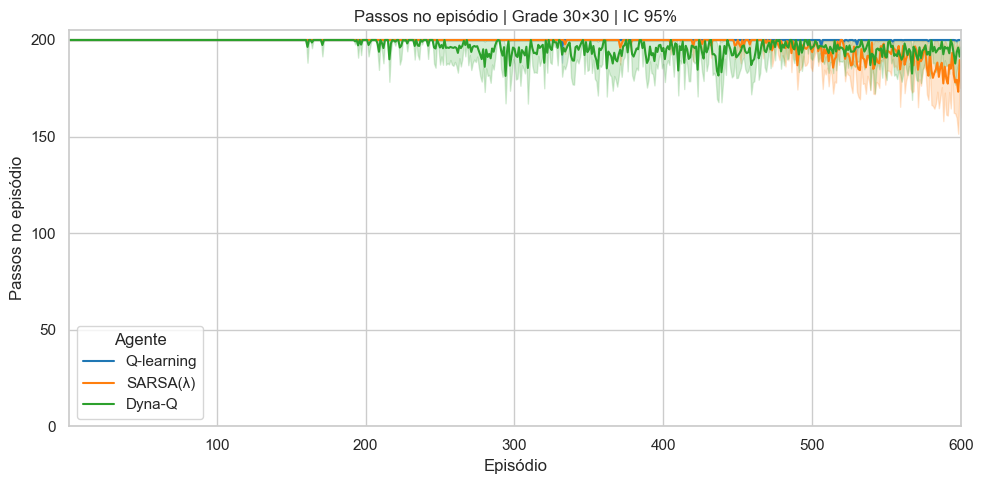

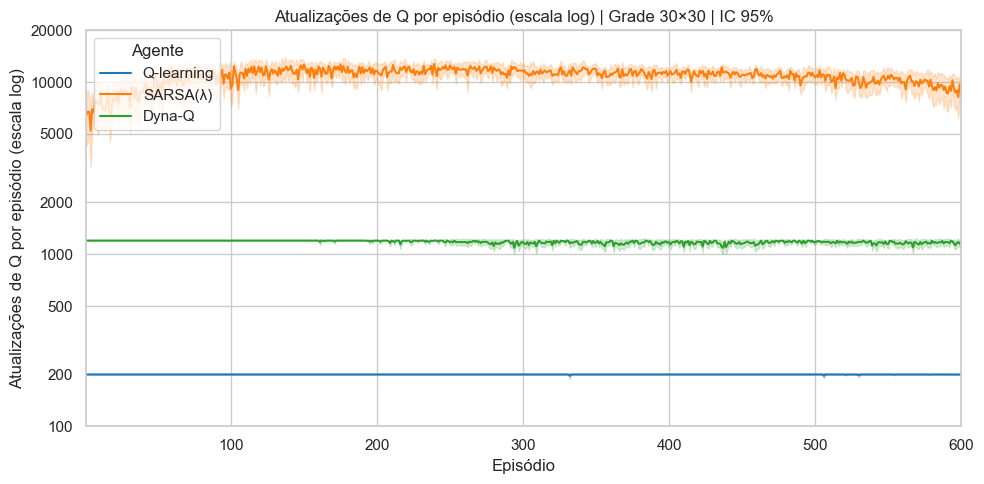

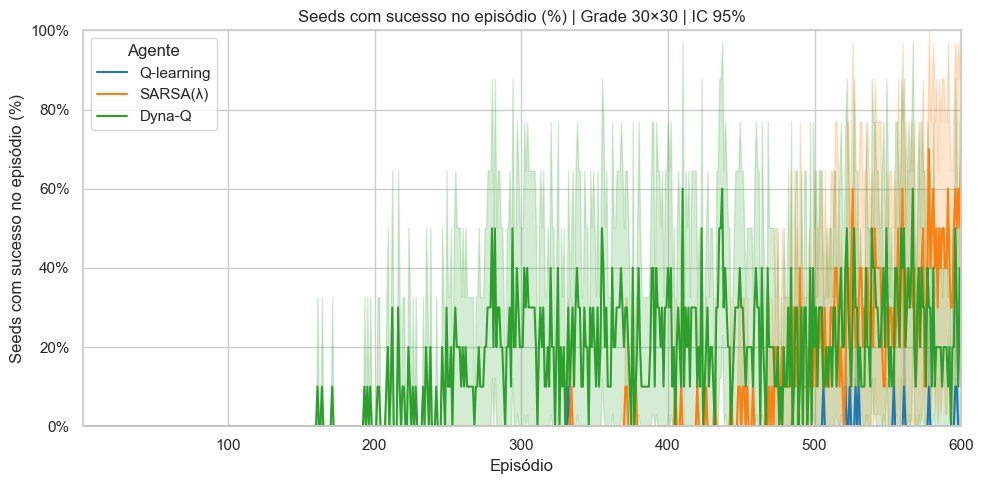

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, ScalarFormatter
import seaborn as sns

def graficos(dados):
    sns.set_theme(style='whitegrid')
    figuras = []
    agentes = ['Q-learning', 'SARSA(lambda)', 'Dyna-Q']
    cores = ['tab:blue', 'tab:orange', 'tab:green']
    medidas = [('episode_steps', 'Passos no episódio', 'passos'),
               ('episode_q_updates', 'Atualizações de Q por episódio (escala log)', 'atualizacoes_q'),
               ('success', 'Seeds com sucesso no episódio (%)', 'sucesso')]
    for grade in (10, 30):
        grupo = dados[dados.grid == grade]
        for coluna, rotulo, nome in medidas:
            fig, ax = plt.subplots(figsize=(10, 5))
            for agente, cor in zip(agentes, cores):
                # Cada episódio reúne uma observação de cada uma das 10 seeds.
                curva = grupo[grupo.algorithm == agente].groupby('episode')[coluna].agg(['mean', 'sem'])
                media = curva['mean']
                inferior = media - 2.262 * curva['sem']
                superior = media + 2.262 * curva['sem']
                # Os intervalos ficam dentro dos valores possíveis da medida.
                if coluna == 'episode_steps':
                    inferior, superior = inferior.clip(0, 200), superior.clip(0, 200)
                elif coluna == 'success':
                    inferior, superior = inferior.clip(0, 1), superior.clip(0, 1)
                ax.plot(curva.index, media, color=cor, label=agente.replace('(lambda)', '(λ)'))
                ax.fill_between(curva.index, inferior, superior, color=cor, alpha=0.2)
            ax.set(xlabel='Episódio', ylabel=rotulo, xlim=(1, 600),
                   title=f'{rotulo} | Grade {grade}×{grade} | IC 95%')
            if coluna == 'episode_steps':
                ax.set_ylim(0, 205)
                ax.set_yticks([0, 50, 100, 150, 200])
            elif coluna == 'episode_q_updates':
                ax.set_yscale('log')
                ax.set_ylim(100, 20000)
                ax.set_yticks([100, 200, 500, 1000, 2000, 5000, 10000, 20000])
                ax.yaxis.set_major_formatter(ScalarFormatter())
                ax.minorticks_off()
            else:
                ax.set_ylim(0, 1)
                ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
            ax.legend(title='Agente')
            fig.tight_layout()
            fig.savefig(PASTA / f'grid{grade}_{nome}.png', dpi=160)
            figuras.append(fig)
    return figuras

figuras = graficos(avaliacao)
plt.show()

## 4.2 Análise de Resultados e Aliasing de Estados

*(Respondam de forma dissertativa, embasando-se nos gráficos gerados acima)*

**a) Qual o melhor algoritmo em termos de eficiência amostralê**
> Escreva sua resposta aqui...

**b) Qual o melhor algoritmo em termos de eficiência computacionalê**
> Escreva sua resposta aqui...

**c) Como a modelagem de estados afetou especificamente o modelo construído pelo Dyna-Q em comparação com o SARSA(λ)? Pense na relação entre as transições reais do ambiente vs nos estados discretizados.**
> Escreva sua resposta detalhada sobre a modelagem de estados aqui...

In [7]:
# ==============================================================================
# GRAVAÇÃO E EXIBIÇÃO DE VÍDEO DOS AGENTES TREINADOS
# ==============================================================================
# Salve um ou mais episódios dos seus agentes que valem a pena serem vistos

## 4.3 Diário de Bordo e Registro de Falhas


**a) O que notadamente falhou nas escolhas de hiperparâmetros (alpha, decaimento de epsilon, λ, N)? Por que falharam?**
> Escreva sua resposta aqui...

**b) Houve alguma dificuldade ou erros na implementação de alguma etapa do projeto? Como foi resolvido?**
> Escreva sua resposta aqui...

**c) O que mais vale a pena relatar que não foi coberto nas demais perguntasó**
> Escreva sua resposta aqui...